In [44]:
# import python libraries

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [45]:
# import csv file
df = pd.read_excel('Diwali Sales Data_DA.xlsx')

In [46]:
df.shape

(11251, 15)

In [47]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002744,Brumley,P00281742,Female,18-25,19,0,Maharashtra,Western,Healthcare,Office,3,188.0,NaN,NaN
1,1004023,Noonan,P00059442,Male,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN
2,1001209,Oshin,P00201342,Female,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
3,1004089,Reichenbach,P00171342,Male,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
4,1000695,Manning,P00296942,Male,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11251 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


In [49]:
#drop unrelated/blank columns
df.drop(['Status', 'unnamed1'], axis=1, inplace=True)

In [50]:
#check for null values
pd.isnull(df).sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [51]:
# drop null values
df.dropna(inplace=True)

In [52]:
# change data type
df['Amount'] = df['Amount'].astype('int')

In [53]:
df['Amount'].dtypes

dtype('int64')

In [54]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='str')

In [55]:
# describe() method returns description of the data in the DataFrame (i.e. count, mean, std, etc)
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.125100e+04,11251.000000,11251.000000,11251.000000,11251.000000
mean,1.003004e+06,35.421207,0.420318,2.489290,9452.711581
std,1.716125e+03,12.754122,0.493632,1.115047,5218.719416
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,1.500000,5443.500000
50%,1.003065e+06,33.000000,0.000000,2.000000,8110.000000
75%,1.004430e+06,43.000000,1.000000,3.000000,12671.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


In [56]:
# use describe() for specific columns
df[['Age', 'Orders', 'Amount']].describe()

,Age,Orders,Amount
count,11251.000000,11251.000000,11251.000000
mean,35.421207,2.489290,9452.711581
std,12.754122,1.115047,5218.719416
min,12.000000,1.000000,188.000000
25%,27.000000,1.500000,5443.500000
50%,33.000000,2.000000,8110.000000
75%,43.000000,3.000000,12671.000000
max,92.000000,4.000000,23952.000000


Gender-wise analysis

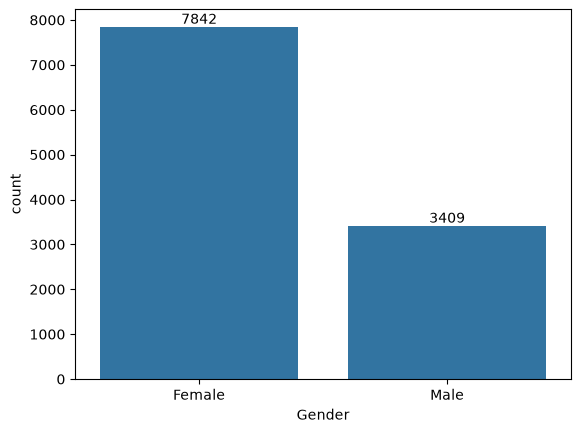

In [57]:
ax = sns.countplot(x='Gender', data=df)
for bars in ax.containers:
    ax.bar_label(bars)

Age Group vs Gender analysis

<Axes: xlabel='Age Group', ylabel='Amount'>

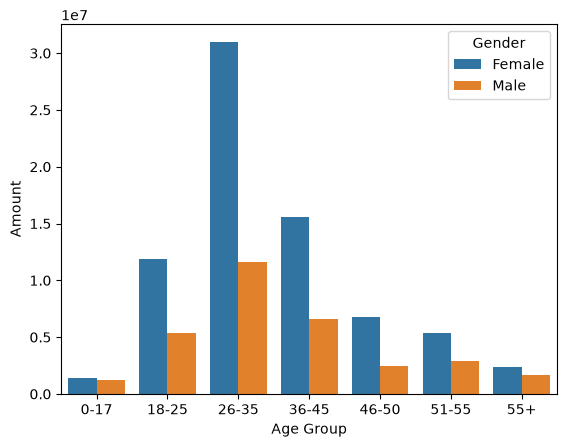

In [58]:
sales_gen = df.groupby(['Age Group', 'Gender'], as_index=False)['Amount'].sum()
sns.barplot(x='Age Group', y='Amount', hue='Gender', data=sales_gen)

State-wise top 10 sales

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Uttar Pradesh'),
  Text(1, 0, 'Maharashtra'),
  Text(2, 0, 'Karnataka'),
  Text(3, 0, 'Delhi'),
  Text(4, 0, 'Madhya Pradesh'),
  Text(5, 0, 'Andhra\xa0Pradesh'),
  Text(6, 0, 'Himachal Pradesh'),
  Text(7, 0, 'Kerala'),
  Text(8, 0, 'Haryana'),
  Text(9, 0, 'Gujarat')])

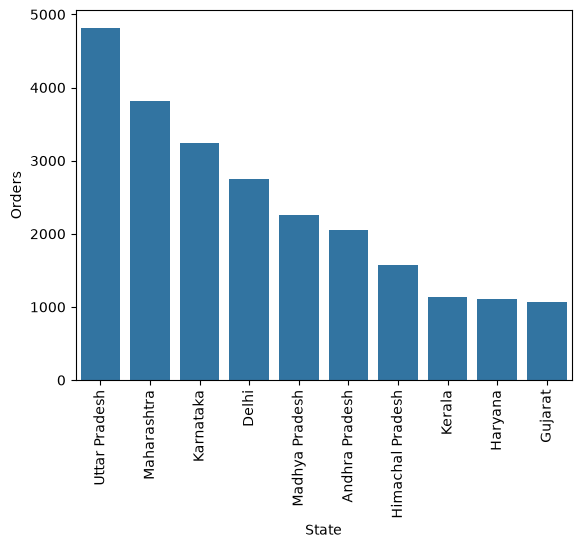

In [59]:
sales_state = df.groupby('State', as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)
sns.barplot(x='State', y='Orders', data=sales_state)
plt.xticks(rotation=90)

Product Category analysis

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Clothing & Apparel'),
  Text(1, 0, 'Food'),
  Text(2, 0, 'Electronics & Gadgets'),
  Text(3, 0, 'Footwear & Shoes'),
  Text(4, 0, 'Household items'),
  Text(5, 0, 'Beauty'),
  Text(6, 0, 'Games & Toys'),
  Text(7, 0, 'Furniture'),
  Text(8, 0, 'Sports Products'),
  Text(9, 0, 'Pet Care')])

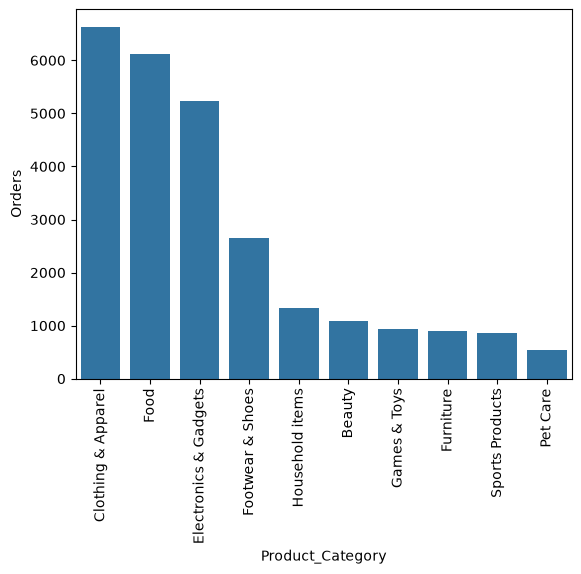

In [60]:
sales_cat = df.groupby('Product_Category', as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)
sns.barplot(x='Product_Category', y='Orders', data=sales_cat)
plt.xticks(rotation=90)

## Conclusion:

Based on the analysis of the Diwali sales dataset, the following key insights were found:

- **Gender:** Female customers made the highest number of purchases, more than double compared to male customers.
- **Age Group:** Customers aged **26-35 years** generated the highest revenue, followed by the 36-45 and 18-25 age groups.
- **State:** **Uttar Pradesh** recorded the highest number of orders, followed by Maharashtra and Karnataka.
- **Product Category:** **Clothing & Apparel** was the most ordered category, followed by Food and Electronics & Gadgets.
- **Occupation:** Customers working in the **IT Sector** contributed the highest sales amount, followed by Healthcare and Aviation.

Overall, businesses should focus marketing campaigns on **women aged 26-35 from Uttar Pradesh, Maharashtra, and Karnataka**, and stock up on **Clothing, Food, and Electronics** ahead of the Diwali season to maximize sales.

complete project on GitHub: https://github.com/sagar00101/Diwali-Sales-Analysis

Thank you!